In [2]:
!pip install numpy pandas scikit-learn demoji textblob torch torchvision torchaudio matplotlib
!python -m textblob.download_corpora


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
[nltk_data] Downloading package brown to /home/sat/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/sat/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/sat/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/sat/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package conll2000 to /home/sat/nltk_data...
[nltk_data]   Package conll2000 is already up-to-date!
[nltk_data] Downloading package movie_reviews to
[nltk_data]     /home/sat/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
Finished.


In [3]:
import numpy as np
import pandas as pd
import sklearn as skl
import demoji as dem
import textblob as tb
import collections as coll
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pickle
dem.download_codes()


/tmp/ipykernel_190609/4036848990.py:11: FutureWarning: The demoji.download_codes attribute is deprecated and will be removed from demoji in a future version. It is an unused attribute as emoji codes are now distributed directly with the demoji package.
  dem.download_codes()


# Reading Data & Data Preprocessing

In [4]:
df = pd.read_csv("semeval-tweets/twitter-training-data.txt", sep="\t", header=None, names=["id", "sentiment", "tweet"])
print(f"NaN tweets: {df['tweet'].isna().sum()}")
df = df.dropna(subset=["tweet"]).reset_index(drop=True)

for i in range(len(df["tweet"])):
  tweet = df.loc[i, "tweet"]
  tweetNoEmoji = dem.replace_with_desc(tweet)
  df.loc[i, "tweet"] = tweetNoEmoji
df

NaN tweets: 1


,id,sentiment,tweet
0,335104872099066692,positive,Felt privileged to play Foo Fighters songs on ...
1,796528524030124618,positive,@AaqibAfzaal Pakistan may be an Islamic countr...
2,760964834217238632,positive,Happy Birthday to the coolest golfer in Bali! ...
3,147713180324524046,negative,@SimpplyA TMILLS is going to Tucson! But the 2...
4,732302280474120023,negative,Hmmmmm where are the #BlackLivesMatter when ma...
...,...,...,...
45020,660374218263817235,neutral,Sunday Cinema | Paul McCartney &amp; David Gil...
45021,739323365061217061,neutral,"14-Aug The day of independence, The day of S..."
45022,681369726697754114,positive,"9 September has arrived, which means Apple's n..."
45023,922217029064536808,positive,So I'll see you all tomorrow for some fun fill...


In [5]:
# test sets
dftests = []

for i in range(1,4):
  dftest = pd.read_csv(f"semeval-tweets/twitter-test{i}.txt", sep="\t", header=None, names=["id", "sentiment", "tweet"])
  print(f"NaN tweets: {df['tweet'].isna().sum()}")
  dftest = dftest.dropna(subset=["tweet"]).reset_index(drop=True)

  for j in range(len(dftest["tweet"])):
    tweet = dftest.loc[j, "tweet"]
    tweetNoEmoji = dem.replace_with_desc(tweet)
    dftest.loc[j, "tweet"] = tweetNoEmoji
  
  dftests.append(dftest)
  print(f"Test set {i} has been loaded.")

NaN tweets: 0
Test set 1 has been loaded.
NaN tweets: 0
Test set 2 has been loaded.
NaN tweets: 0
Test set 3 has been loaded.


In [6]:
print(len(dftests))
dftests[0] # twitter-test1.txt

3


,id,sentiment,tweet
0,163361196206957578,neutral,Candids: Heading to the Chateau Marmont in Wes...
1,768006053969268950,negative,@Dont__KAY_me omg same I was reading it in sch...
2,742616104384772304,neutral,Watching MTV Hits! The Wanted Chasing the sun!
3,102313285628711403,neutral,"Bing one-ups knowledge graph, hires Encyclopae..."
4,653274888624828198,neutral,"On Thursday, concealed-carry gun license holde..."
...,...,...,...
3526,897427103459983282,positive,"@heavyoilcountry right you are, they could end..."
3527,494418545323766863,neutral,We will have to think about continuing in UPA:...
3528,556020888361859268,positive,ladies come throw that ass and niggas come thr...
3529,683639126147064420,neutral,@MandiieeKillaaa are you going to laidback Luk...


In [7]:
print(df["sentiment"].value_counts(dropna=False))

sentiment
neutral     20748
positive    15960
negative     8317
Name: count, dtype: int64


### Preprocess

In [8]:
# lower case everything
df["tweet"] = df['tweet'].str.lower()
for i in range(3):
  dftests[i]["tweet"] = dftests[i]['tweet'].str.lower()
df

,id,sentiment,tweet
0,335104872099066692,positive,felt privileged to play foo fighters songs on ...
1,796528524030124618,positive,@aaqibafzaal pakistan may be an islamic countr...
2,760964834217238632,positive,happy birthday to the coolest golfer in bali! ...
3,147713180324524046,negative,@simpplya tmills is going to tucson! but the 2...
4,732302280474120023,negative,hmmmmm where are the #blacklivesmatter when ma...
...,...,...,...
45020,660374218263817235,neutral,sunday cinema | paul mccartney &amp; david gil...
45021,739323365061217061,neutral,"14-aug the day of independence, the day of s..."
45022,681369726697754114,positive,"9 september has arrived, which means apple's n..."
45023,922217029064536808,positive,so i'll see you all tomorrow for some fun fill...


In [9]:
# Remove urls
df["tweet"] = df['tweet'].str.replace(r'https?://\S+', '', regex=True)
for i in range(3):
  dftests[i]["tweet"] = dftests[i]['tweet'].str.replace(r'https?://\S+', '', regex=True)

In [10]:
# Removing whitespace and \n
df["tweet"] = df["tweet"].str.replace(r'\s+', ' ', regex=True).str.strip()
for i in range(3):
  dftests[i]["tweet"] = dftests[i]["tweet"].str.replace(r'\s+', ' ', regex=True).str.strip()

In [11]:
# remove punctuation
df["tweet"] = df['tweet'].str.replace(r'(?<![^\w\s])[^\w\s](?![^\w\s])', '', regex=True)
for i in range(3):
  dftests[i]["tweet"] = dftests[i]['tweet'].str.replace(r'(?<![^\w\s])[^\w\s](?![^\w\s])', '', regex=True)
df["tweet"].dtype

<StringDtype(storage='python', na_value=nan)>

In [12]:
# Remove non english characters
for i in range(len(df["tweet"])):
  tweet = df.loc[i, "tweet"]
  df.loc[i, "tweet"] = tweet.encode('ascii',errors='ignore').decode('ascii')

for i in range(3):
  for j in range(len(dftests[i]["tweet"])):
    tweet = dftests[i].loc[j, "tweet"]
    dftests[i].loc[j, "tweet"] = tweet.encode('ascii',errors='ignore').decode('ascii')

In [13]:
# Lemmatisation with Texblob
for i in range(len(df["tweet"])):
    blob = tb.TextBlob(df.loc[i, "tweet"])
    lemmatised = []
    for word, tag in blob.tags:
        if tag.startswith('VB'):
            lemmatised.append(word.lemmatize('v'))
        elif tag.startswith('NN'):
            lemmatised.append(word.lemmatize('n'))
        elif tag.startswith('JJ'):
            lemmatised.append(word.lemmatize('a'))
        else:
            lemmatised.append(word)
    df.loc[i, "tweet"] = " ".join(lemmatised)

df

,id,sentiment,tweet
0,335104872099066692,positive,felt privilege to play foo fighter song on gui...
1,796528524030124618,positive,aaqibafzaal pakistan may be an islamic country...
2,760964834217238632,positive,happy birthday to the cool golfer in bali tjvi...
3,147713180324524046,negative,simpplya tmills be go to tucson but the 29th a...
4,732302280474120023,negative,hmmmmm where be the blacklivesmatter when matt...
...,...,...,...
45020,660374218263817235,neutral,sunday cinema paul mccartney amp david gilmour...
45021,739323365061217061,neutral,14aug the day of independence the day of sacri...
45022,681369726697754114,positive,9 september have arrive which mean apple new i...
45023,922217029064536808,positive,so ill see you all tomorrow for some fun fill ...


In [14]:
for i in range(3):
  for j in range(len(dftests[i]["tweet"])):
    blob = tb.TextBlob(dftests[i].loc[j, "tweet"])
    lemmatised = []
    for word, tag in blob.tags:
      if tag.startswith('VB'):
        lemmatised.append(word.lemmatize('v'))
      elif tag.startswith('NN'):
        lemmatised.append(word.lemmatize('n'))
      elif tag.startswith('JJ'):
        lemmatised.append(word.lemmatize('a'))
      else:
        lemmatised.append(word)
    dftests[i].loc[j, "tweet"] = " ".join(lemmatised)

dftests[0]

,id,sentiment,tweet
0,163361196206957578,neutral,candids head to the chateau marmont in west ho...
1,768006053969268950,negative,dont__kay_me omg same i be read it in school a...
2,742616104384772304,neutral,watch mtv hit the wanted chase the sun
3,102313285628711403,neutral,bing oneups knowledge graph hire encyclopaedia...
4,653274888624828198,neutral,on thursday concealedcarry gun license holder ...
...,...,...,...
3526,897427103459983282,positive,heavyoilcountry right you be they could end up...
3527,494418545323766863,neutral,we will have to think about continue in upa ma...
3528,556020888361859268,positive,lady come throw that as and niggas come throw ...
3529,683639126147064420,neutral,mandiieekillaaa be you go to laidback luke tom...


### N-Gram and then BoW the dataset

In [15]:
X, y = "tweet", "sentiment"

In [16]:
df[y] = df[y].replace({"positive": 2, "neutral": 1, "negative": 0}).astype(int)
for i in range(3):
  dftests[i][y] = dftests[i][y].replace({"positive": 2, "neutral": 1, "negative": 0}).astype(int)

In [17]:
df[y].value_counts()

sentiment
1    20748
2    15960
0     8317
Name: count, dtype: int64

In [18]:
dftests[0][y].value_counts()

sentiment
1    1504
2    1470
0     557
Name: count, dtype: int64

# Classifier 1: SVM

In [19]:
def modelFunc():
    bestC = 0
    bestF1 = -np.inf
    bestWeights = {}
    
    for c in [0.5, 1.0, 1.3, 1.5, 2.0]:
        for weights in [{0: 0.7, 1: 0.15, 2: 0.3}, {0: 2.0, 1: 0.5, 2: 1.0}, {0: 1.5, 1: 0.3, 2: 0.5}]:
            pipeCV = skl.pipeline.Pipeline([
                ('tfidf', skl.feature_extraction.text.TfidfVectorizer(ngram_range=(1, 3), sublinear_tf=True, min_df=3, max_df=0.95)),
                ('svm', skl.svm.LinearSVC(C=c, max_iter=10000, class_weight=weights))
            ])
            scores = skl.model_selection.cross_val_score(pipeCV, df[X], df[y], cv=5, scoring='f1_macro')
            mean_f1 = scores.mean()
            print(f"C={c}, weights={weights}: CV F1={mean_f1:.4f} (+/- {scores.std():.4f})")
    
            if mean_f1 > bestF1:
                bestF1 = mean_f1
                bestC = c
                bestWeights = weights
    
    print(f"\nBest: C={bestC}, weights={bestWeights}, CV F1={bestF1:.4f}")
    
    pipe = skl.pipeline.Pipeline([
        ('tfidf', skl.feature_extraction.text.TfidfVectorizer(ngram_range=(1, 3), sublinear_tf=True, min_df=3, max_df=0.95)),
        ('svm', skl.svm.LinearSVC(C=bestC, max_iter=10000, class_weight=bestWeights))
    ])
    return bestC, bestWeights, bestF1, pipe

In [20]:
bestC, bestWeights, bestF1, pipe = modelFunc()
print("DONE CV.")
bestC, bestF1, bestWeights

C=0.5, weights={0: 0.7, 1: 0.15, 2: 0.3}: CV F1=0.6229 (+/- 0.0035)
C=0.5, weights={0: 2.0, 1: 0.5, 2: 1.0}: CV F1=0.6269 (+/- 0.0038)
C=0.5, weights={0: 1.5, 1: 0.3, 2: 0.5}: CV F1=0.6261 (+/- 0.0026)
C=1.0, weights={0: 0.7, 1: 0.15, 2: 0.3}: CV F1=0.6206 (+/- 0.0038)
C=1.0, weights={0: 2.0, 1: 0.5, 2: 1.0}: CV F1=0.6180 (+/- 0.0029)
C=1.0, weights={0: 1.5, 1: 0.3, 2: 0.5}: CV F1=0.6205 (+/- 0.0027)
C=1.3, weights={0: 0.7, 1: 0.15, 2: 0.3}: CV F1=0.6184 (+/- 0.0035)
C=1.3, weights={0: 2.0, 1: 0.5, 2: 1.0}: CV F1=0.6137 (+/- 0.0032)
C=1.3, weights={0: 1.5, 1: 0.3, 2: 0.5}: CV F1=0.6176 (+/- 0.0033)
C=1.5, weights={0: 0.7, 1: 0.15, 2: 0.3}: CV F1=0.6173 (+/- 0.0030)
C=1.5, weights={0: 2.0, 1: 0.5, 2: 1.0}: CV F1=0.6118 (+/- 0.0033)
C=1.5, weights={0: 1.5, 1: 0.3, 2: 0.5}: CV F1=0.6153 (+/- 0.0029)
C=2.0, weights={0: 0.7, 1: 0.15, 2: 0.3}: CV F1=0.6148 (+/- 0.0031)
C=2.0, weights={0: 2.0, 1: 0.5, 2: 1.0}: CV F1=0.6064 (+/- 0.0034)
C=2.0, weights={0: 1.5, 1: 0.3, 2: 0.5}: CV F1=0.6106 (+/

(0.5, np.float64(0.6268933037619587), {0: 2.0, 1: 0.5, 2: 1.0})

In [21]:
# Use the best model
pipe.fit(df[X], df[y])
svmF1s = []
svmPredsArr = []
for i in range(3):
  predsSVM = pipe.predict(dftests[i][X])
  svmPredsArr.append(predsSVM)
  f1 = skl.metrics.f1_score(dftests[i][y], predsSVM, labels=[0, 2], average='macro')
  svmF1s.append(f1)

svmF1s

[0.6230652963489347, 0.6455180219308554, 0.5729310494786853]

In [22]:
for i in range(3):
  mcm = skl.metrics.multilabel_confusion_matrix(dftests[i][y], svmPredsArr[i], labels=[0, 1, 2])
  print(f"------------ Set {i} ----------------")
  for j, label in enumerate(["negative", "neutral", "positive"]):
    tn, fp, fn, tp = mcm[j].ravel()
    print(f"{label}: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

------------ Set 0 ----------------
negative: TP=281, FP=197, FN=276, TN=2777
neutral: TP=996, FP=529, FN=508, TN=1498
positive: TP=1054, FP=474, FN=416, TN=1587
------------ Set 1 ----------------
negative: TP=107, FP=83, FN=95, TN=1568
neutral: TP=388, FP=260, FN=281, TN=924
positive: TP=744, FP=271, FN=238, TN=600
------------ Set 2 ----------------
negative: TP=178, FP=211, FN=185, TN=1805
neutral: TP=652, FP=414, FN=331, TN=982
positive: TP=658, FP=266, FN=375, TN=1080


In [23]:
for i in range(3):
  print(f"------------ Set {i} ----------------")
  report = skl.metrics.classification_report(dftests[i][y], svmPredsArr[i])
  print(report)

------------ Set 0 ----------------
              precision    recall  f1-score   support

           0       0.59      0.50      0.54       557
           1       0.65      0.66      0.66      1504
           2       0.69      0.72      0.70      1470

    accuracy                           0.66      3531
   macro avg       0.64      0.63      0.63      3531
weighted avg       0.66      0.66      0.66      3531

------------ Set 1 ----------------
              precision    recall  f1-score   support

           0       0.56      0.53      0.55       202
           1       0.60      0.58      0.59       669
           2       0.73      0.76      0.75       982

    accuracy                           0.67      1853
   macro avg       0.63      0.62      0.63      1853
weighted avg       0.67      0.67      0.67      1853

------------ Set 2 ----------------
              precision    recall  f1-score   support

           0       0.46      0.49      0.47       363
           1       0.

# Classifier 2: Logistic Regression

In [24]:
param_grid = {
    'lr__C': [0.1, 0.5, 1.0, 2.0],
}

In [25]:
pipe = skl.pipeline.Pipeline([
    ('tfidf', skl.feature_extraction.text.TfidfVectorizer(ngram_range=(1, 3), sublinear_tf=True, min_df=3, max_df=0.95)),
    ('lr', skl.linear_model.LogisticRegression(max_iter=10000, class_weight=bestWeights))
])

griddy = skl.model_selection.GridSearchCV(estimator=pipe, param_grid=param_grid, 
                           cv=5, n_jobs=-1, verbose=2, scoring = 'f1_macro')
griddy.fit(df[X], df[y])

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END ..........................................lr__C=0.1; total time=  16.6s
[CV] END ..........................................lr__C=0.1; total time=  19.0s
[CV] END ..........................................lr__C=0.1; total time=  18.9s
[CV] END ..........................................lr__C=0.1; total time=  20.0s
[CV] END ..........................................lr__C=0.5; total time=  21.0s
[CV] END ..........................................lr__C=0.1; total time=  20.5s
[CV] END ..........................................lr__C=1.0; total time=  20.7s
[CV] END ..........................................lr__C=0.5; total time=  22.3s
[CV] END ..........................................lr__C=0.5; total time=  21.5s
[CV] END ..........................................lr__C=0.5; total time=  23.1s
[CV] END ..........................................lr__C=0.5; total time=  23.2s
[CV] END ........................................

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=10000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lr__C': [0.1, 0.5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate pa

In [26]:
lrcF1s = []
lrcPredsArr = []
for i in range(3):
  predsLR = griddy.predict(dftests[i][X])
  lrcPredsArr.append(predsLR)
  f1 = skl.metrics.f1_score(dftests[i][y], predsLR, labels=[0, 2], average='macro')
  lrcF1s.append(f1)

lrcF1s

[0.6425835805551638, 0.6479411764705882, 0.6119873606146771]

In [27]:
for i in range(3):
  print(f"------------ Set {i} ----------------")
  report = skl.metrics.classification_report(dftests[i][y], lrcPredsArr[i])
  print(report)

------------ Set 0 ----------------
              precision    recall  f1-score   support

           0       0.58      0.59      0.58       557
           1       0.69      0.56      0.62      1504
           2       0.65      0.77      0.70      1470

    accuracy                           0.65      3531
   macro avg       0.64      0.64      0.64      3531
weighted avg       0.66      0.65      0.65      3531

------------ Set 1 ----------------
              precision    recall  f1-score   support

           0       0.52      0.57      0.55       202
           1       0.63      0.47      0.54       669
           2       0.70      0.81      0.75       982

    accuracy                           0.66      1853
   macro avg       0.62      0.62      0.61      1853
weighted avg       0.65      0.66      0.65      1853

------------ Set 2 ----------------
              precision    recall  f1-score   support

           0       0.45      0.63      0.53       363
           1       0.

# Classifier 3: Long Short-Term Memory LSTM

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using: {device}")

Using: cuda


In [29]:
class LSTM(nn.Module):
  def __init__(self, vocabSize, embedding = 100, hidden = 64, numlayers = 2, output = 3, embeddingMat = None):
    super().__init__()
    self.hidden = hidden
    self.numlayers = numlayers

    self.embedding = nn.Embedding(vocabSize, embedding)
    if embeddingMat is not None:
      self.embedding.weight = nn.Parameter(torch.FloatTensor(embeddingMat))
      self.embedding.weight.requires_grad = False

    # LSTM: takes (batch, seq_len, input_dim) -> (batch, seq_len, hidden_dim)
    self.lstm = nn.LSTM(
      input_size = embedding,
      hidden_size = hidden,
      num_layers = numlayers,
      batch_first = True, # to ensure input is (batch, seq, features)
      dropout=0.3
    )

    # linear layer
    self.dropout = nn.Dropout(0.3)
    self.fc = nn.Linear(hidden, output)
  
  def forward(self, x):
    embedded = self.embedding(x)
    h0 = torch.zeros(self.numlayers, x.size(0), self.hidden).to(x.device)
    c0 = torch.zeros(self.numlayers, x.size(0), self.hidden).to(x.device)
    out, (hn, cn) = self.lstm(embedded, (h0, c0))
    lasthidden = self.dropout(out[:, -1, :])
    pred = self.fc(lasthidden)
    return pred

In [30]:
# Split the tweets into wordforms
allwords = []
for tweet in df["tweet"]:
  allwords.extend(tweet.split())

# Count frequencies & keep most common
wordCounts = coll.Counter(allwords)
maxWords = 5000

vocab = { word : idx + 1 for idx, (word, _) in enumerate(wordCounts.most_common(maxWords)) }
vocabSize = len(vocab) + 1

print(f"Vocab size: {vocabSize}")

#
# trainset = torch.utils.data.TensorDataset()

Vocab size: 5001


In [31]:
# Loading the GloVe vectors
glove = {}
with open("data/glove.6B.100d.txt", encoding = "utf-8") as file_:
  for line in file_:
    parts = line.split()
    word = parts[0]
    vector = np.array(parts[1:], dtype = np.float32)
    glove[word] = vector

In [32]:
print(f"Loaded {len(glove)} GloVe vectors")

Loaded 400000 GloVe vectors


In [33]:
embedDim = 100
embedMatrix = np.zeros((vocabSize, embedDim))

found, missing = 0, 0

for word, idx in vocab.items():
  if word in glove:
    embedMatrix[idx] = glove[word]
    found += 1
  else:
    missing += 1



In [34]:
print(f"Found: {found}, Missing: {missing}")

Found: 4773, Missing: 227


In [35]:
maxLen = 50

def tweetsToSeqs(tweets, vocab, maxLen):
  seqs = []
  for tweet in tweets:
    indices = [ vocab.get(word, 0) for word in tweet.split() ] # 0 if unknown

    # Truncate or pad
    if len(indices) >= maxLen:
      indices = indices[:maxLen]
    else:
      indices = indices + [0] * (maxLen - len(indices))
    
    seqs.append(indices)
  return np.array(seqs)

In [36]:
XtrainSeq = tweetsToSeqs(df["tweet"], vocab, maxLen)
XtestSeqs = []
for i in range(len(dftests)):
  XtestSeqs.append(tweetsToSeqs(dftest["tweet"], vocab, maxLen))
XtrainSeq.shape # should be (45025, 50)

(45025, 50)

In [37]:
epochs = 400
batch = 64 # batch size

In [42]:
for i in range(3):
  dftests[i] = dftests[i].dropna(subset=["tweet"]).reset_index(drop=True)
  dftests[i] = dftests[i][dftests[i]["tweet"].str.strip() != ""].reset_index(drop=True)

In [43]:
XtrainTens = torch.LongTensor(XtrainSeq)
YtrainTens = torch.LongTensor(df[y].values)
XtestTens = []
YtestTens = []
for i in range(len(XtestSeqs)):
  print(f"Test {i+1}: X={XtestSeqs[i].shape}, df={len(dftests[i])}")
  Xtest = torch.LongTensor(XtestSeqs[i])
  XtestTens.append(Xtest)

  Ytest = torch.LongTensor(dftests[i][y].values)
  YtestTens.append(Ytest)

trainset = torch.utils.data.TensorDataset(XtrainTens, YtrainTens)
trainloader = torch.utils.data.DataLoader(trainset, batch_size = batch, shuffle = True)
testsets = []
testloaders = []
for i in range(len(XtestTens)):
  testset = torch.utils.data.TensorDataset(XtestTens[i], YtestTens[i])
  testsets.append(testset)

  testloader = torch.utils.data.DataLoader(testset, batch_size = batch, shuffle = True)
  testloaders.append(testloader)

Test 1: X=(2379, 50), df=3531
Test 2: X=(2379, 50), df=1853
Test 3: X=(2379, 50), df=2379


AssertionError: Size mismatch between tensors

In [ ]:
model = LSTM(
    vocabSize = vocabSize,
    embedding = 100,
    hidden = 256,
    output = 3,
    embeddingMat = embedMatrix,
)
model = model.to(device)
# Verify embedding is frozen
print(f"Embedding frozen: {not model.embedding.weight.requires_grad}")

Embedding frozen: True


In [ ]:
weights = torch.FloatTensor([2.0, 0.5, 1.0]).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimiser = torch.optim.Adam(model.parameters(), lr = 0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimiser, patience=5, factor=0.5)

In [ ]:
print(f"Using: {device}")

Using: cuda


In [ ]:
# Now train it
losses = []
for epoch in range(epochs):
  model.train()
  epochLoss = 0
  for batchX, batchY in trainloader:
    batchX = batchX.to(device)
    batchY = batchY.to(device)
    preds = model(batchX)
    loss = criterion(preds, batchY)

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()  # actually update weights

    epochLoss += loss.item()

  aveLoss = epochLoss / len(trainloader)
  losses.append(aveLoss)
  scheduler.step(aveLoss)  # once per epoch, after computing avg loss

  if (epoch + 1) % 10 == 0:
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {aveLoss:.6f}")

Epoch [10/1000], Loss: 0.784076
Epoch [20/1000], Loss: 0.723826
Epoch [30/1000], Loss: 0.668521
Epoch [40/1000], Loss: 0.605601
Epoch [50/1000], Loss: 0.546870
Epoch [60/1000], Loss: 0.487975
Epoch [70/1000], Loss: 0.434099
Epoch [80/1000], Loss: 0.389082
Epoch [90/1000], Loss: 0.340363
Epoch [100/1000], Loss: 0.296908
Epoch [110/1000], Loss: 0.258096
Epoch [120/1000], Loss: 0.222296
Epoch [130/1000], Loss: 0.190111
Epoch [140/1000], Loss: 0.161877
Epoch [150/1000], Loss: 0.141654
Epoch [160/1000], Loss: 0.128935
Epoch [170/1000], Loss: 0.110020
Epoch [180/1000], Loss: 0.103816
Epoch [190/1000], Loss: 0.087379
Epoch [200/1000], Loss: 0.078432
Epoch [210/1000], Loss: 0.066912
Epoch [220/1000], Loss: 0.060918
Epoch [230/1000], Loss: 0.053707
Epoch [240/1000], Loss: 0.030408
Epoch [250/1000], Loss: 0.017752
Epoch [260/1000], Loss: 0.013470
Epoch [270/1000], Loss: 0.009966
Epoch [280/1000], Loss: 0.008575
Epoch [290/1000], Loss: 0.008224
Epoch [300/1000], Loss: 0.004679
Epoch [310/1000], L

In [ ]:
# Save everything
torch.save(model.state_dict(), "lstm_model.pth")

with open("vocab.pkl", "wb") as f:
  pickle.dump(vocab, f)

np.save("embeddingmatrix.npy", embedMatrix)

In [ ]:
# Load later
vocab = None
with open("vocab.pkl", "rb") as f:
    vocab = pickle.load(f)

embedMatrix = np.load("embeddingmatrix.npy")

model = LSTM(vocabSize=vocabSize, hidden=256, embeddingMat=embedMatrix)
model.load_state_dict(torch.load("lstm_model.pth"))
model.to(device)
model.eval()

LSTM(
  (embedding): Embedding(5001, 100)
  (lstm): LSTM(100, 256, batch_first=True, dropout=0.3)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)

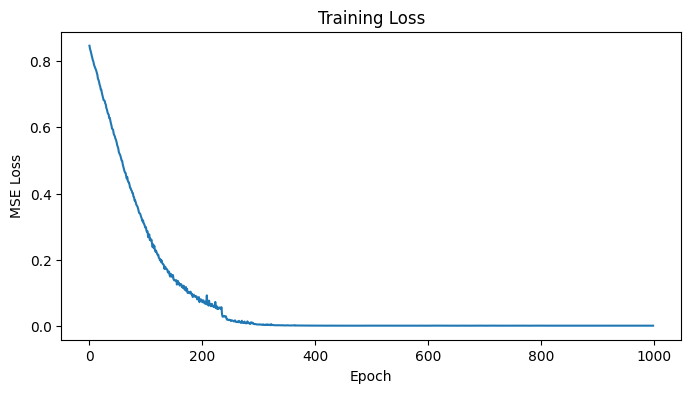

In [ ]:
# plot loss
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.show()

In [ ]:
model.eval()
lstmPredsArr = []
yTrues = []
with torch.no_grad():
  for i in range(len(XtestTens)):
    outputs = model(XtestTens[i].to(device))
    _, predicted = torch.max(outputs, 1)  # get class with highest score

    # Convert back to numpy for sklearn metrics
    lstmPredsArr.append(predicted.cpu().numpy()) # move back to CPU for sklearn
    yTrue = YtestTens[i].numpy()


In [ ]:
# F1 score (pos + neg only, as per spec)
for i in range(len(XtrainTens)):
  print(f"------------ Set {i} ----------------")
  predsLSTM = lstmPredsArr[i]
  yTrue = yTrues[i]
  f1 = skl.metrics.f1_score(yTrue, predsLSTM, labels=[0, 2], average='macro')
  print(f"Macro F1 (pos+neg): {f1:.4f}")

  # Full classification report
  print(skl.metrics.classification_report(yTrue, predsLSTM, target_names=["negative", "neutral", "positive"]))

  # Confusion matrix
  mcm = skl.metrics.multilabel_confusion_matrix(yTrue, predsLSTM, labels=[0, 1, 2])
  for j, label in enumerate(["negative", "neutral", "positive"]):
      tn, fp, fn, tp = mcm[j].ravel()
      print(f"{label}: TP={tp}, FP={fp}, FN={fn}, TN={tn}")

Macro F1 (pos+neg): 0.5436
              precision    recall  f1-score   support

    negative       0.57      0.38      0.46       557
     neutral       0.56      0.69      0.62      1504
    positive       0.67      0.60      0.63      1470

    accuracy                           0.60      3531
   macro avg       0.60      0.56      0.57      3531
weighted avg       0.61      0.60      0.60      3531

negative: TP=211, FP=158, FN=346, TN=2816
neutral: TP=1042, FP=803, FN=462, TN=1224
positive: TP=880, FP=437, FN=590, TN=1624
